In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [9]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

In [10]:
print(x_train.shape)   # (50000, 32, 32, 3)
print(y_train.shape)   # (50000, 1)

class_names = ["airplane", "automobile", "bird", "cat", "deer",        
       "dog", "frog", "horse", "ship", "truck"]

(50000, 32, 32, 3)
(50000, 1)


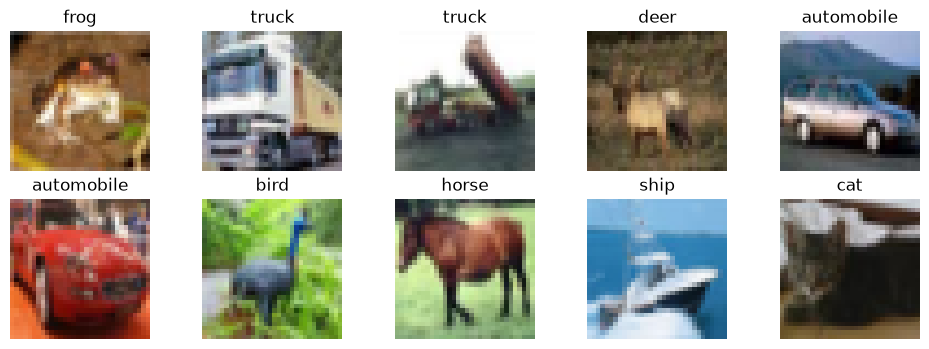

In [11]:
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.show()

In [12]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

In [14]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32,(3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32,(3,3), padding="same", activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Conv2D(64,(3,3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64,(3,3), padding="same", activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,168,746 (8.27 MB)

 Trainable params: 2,168,554 (8.27 MB)

 Non-trainable params: 192 (768.00 B)

In [15]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

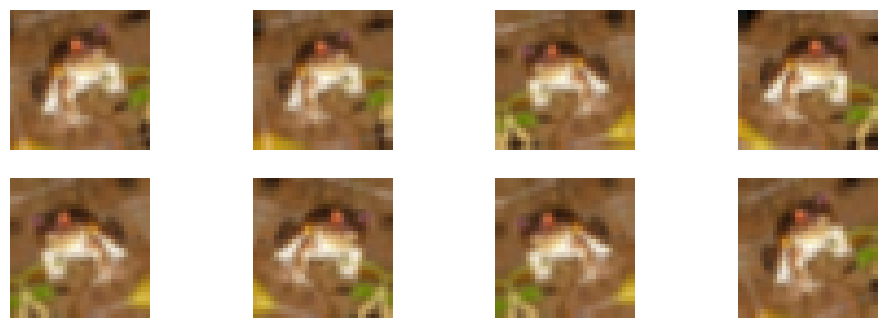

In [18]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

plt.figure(figsize=(12, 4))
for i in range(8):
    img = data_augmentation(x_train[0:1], training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(img[0])
    plt.axis("off")

plt.show()

In [20]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("best_cnn.keras", save_best_only=True)
]

history = model.fit(
    x_train, y_train,
    epochs= 30,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks
)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 82s 115ms/step - accuracy: 0.4948 - loss: 1.3787 - val_accuracy: 0.5920 - val_loss: 1.1321
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 72s 101ms/step - accuracy: 0.5797 - loss: 1.1810 - val_accuracy: 0.6470 - val_loss: 1.0003
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 70s 100ms/step - accuracy: 0.6339 - loss: 1.0421 - val_accuracy: 0.6858 - val_loss: 0.8979
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 72s 103ms/step - accuracy: 0.6737 - loss: 0.9381 - val_accuracy: 0.7318 - val_loss: 0.7706
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 98s 140ms/step - accuracy: 0.6965 - loss: 0.8747 - val_accuracy: 0.7412 - val_loss: 0.7448
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 85s 121ms/step - accuracy: 0.7207 - loss: 0.8086 - val_accuracy: 0.7366 - val_loss: 0.7693
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 72s 102ms/step - accuracy: 0.7379 - loss: 0.7574 - val_accuracy: 0.7630 - val_loss: 0.7038
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 69s 97ms/step - accuracy: 0.7508 - loss: 0.

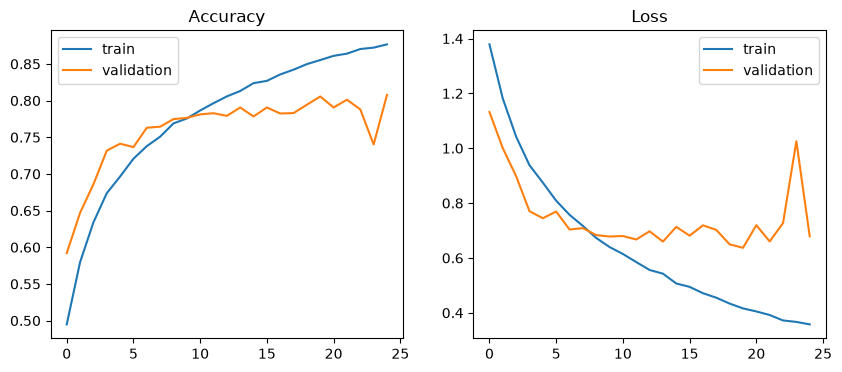

In [21]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"), plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"), plt.legend()
plt.show()

In [22]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("test accuracy:", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.7917 - loss: 0.6642
test accuracy: 0.791700005531311


313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step
              precision    recall  f1-score   support

    airplane       0.82      0.80      0.81      1000
  automobile       0.90      0.91      0.90      1000
        bird       0.65      0.73      0.69      1000
         cat       0.63      0.58      0.60      1000
        deer       0.77      0.74      0.75      1000
         dog       0.76      0.68      0.72      1000
        frog       0.75      0.91      0.82      1000
       horse       0.89      0.81      0.85      1000
        ship       0.91      0.87      0.89      1000
       truck       0.87      0.90      0.89      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000



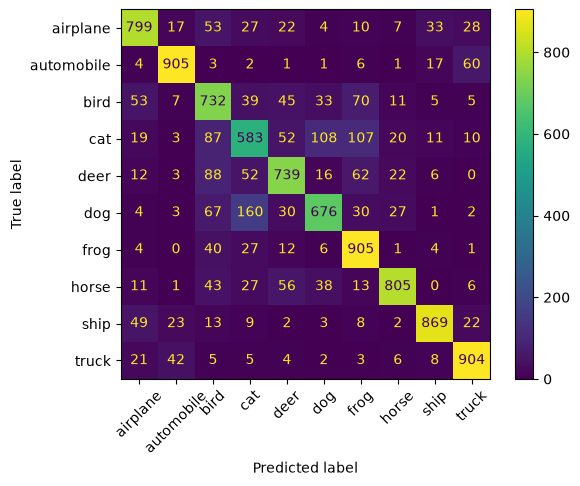

In [23]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(model.predict(x_test), axis=-1)
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step


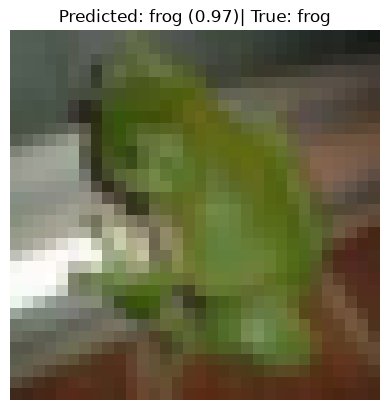

In [24]:
idx = 7
img = x_test[idx]
probs = model.predict(img[np.newaxis, ...])[0]

plt.imshow(img)
plt.title(f"Predicted: {class_names[np.argmax(probs)]} ({probs[np.argmax(probs)]:.2f})"
          f"| True: {class_names[y_test[idx]]}")

plt.axis("off")
plt.show()